# MUC – Training und Spielleistung

Dieses Notebook liest die von `python -m ai.train` geschriebenen CSV-Dateien. Es trainiert **nicht automatisch** und kann parallel zu einem laufenden Training geöffnet werden. Nach neuen Updates: **Run → Run All Cells**.

Wähle unten mit `RUN_NAMES` einen oder mehrere Runs in der gewünschten Reihenfolge, zum Beispiel `["muc5", "muc5-1", "muc5-2"]`. Für einen einzelnen Run genügt `["muc5-2"]`.

Die Runs werden zu einem gemeinsamen Verlauf verbunden. Fortlaufende Schrittzähler bleiben erhalten; zurückgesetzte Zähler werden auf der Plotachse hinter den vorherigen Run verschoben. Dezente vertikale Linien markieren die Übergänge in den Zeitverlaufsplots; im Bildtitel steht die Reihenfolge. Die Glättung beginnt pro Run neu. Alle Runs müssen dieselbe Strecke verwenden. Loss-Gewichte werden pro Run gelesen; Returns bei unterschiedlichen Reward-Konfigurationen bleiben nur eingeschränkt vergleichbar.


In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
import json
import math
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ai" / "train.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from ai.analysis_data import load_runs, number
from ai.environment import CrewEnv

RUN_NAMES = ["muc5", "muc5-1", "muc5-2", "muc5-3", "muc5-4"]  # Reihenfolge der Runs; einzeln z. B. ["muc5-2"].
SMOOTHING = 5
SAVE_FIGURES = False  # Optional PNGs unter PLOT_DIR speichern.
plt.rcParams.update({"figure.figsize": (12, 7), "axes.grid": True, "grid.alpha": 0.2})

runs = load_runs(ROOT, RUN_NAMES)
metrics = [row for run in runs for row in run.metrics]
episodes = [row for run in runs for row in run.episodes]
PLOT_DIR = runs[-1].directory / "plots"
if len(runs) > 1:
    PLOT_DIR = PLOT_DIR / ("concat-" + "__".join(run.name for run in runs))

def update_key(row):
    return row["run_name"], int(row["update"])

def series(key, rows=None):
    pairs = [(number(r, "plot_steps"), number(r, key)) for r in (metrics if rows is None else rows)]
    return np.array([(x, y) for x, y in pairs if math.isfinite(x) and math.isfinite(y)]).reshape(-1, 2)

def rolling(values, width=SMOOTHING):
    return np.array([np.mean(values[max(0, i-width+1):i+1]) for i in range(len(values))])

def plot_metric(ax, key, label=None, smooth=False, scale=1, **kwargs):
    labeled = False
    for run in runs:
        points = series(key, run.metrics)
        if not len(points):
            continue
        x, y = points.T
        y = y * scale
        if smooth:
            ax.plot(x, y, alpha=0.2, **kwargs)
            y = rolling(y)
        ax.plot(x, y, label=(label or key) if not labeled else "_nolegend_",
                marker="." if len(y) < 20 else None, **kwargs)
        labeled = True
    ax.set_xlabel("Spielentscheidungen im Training")

def finish(fig, name, time_axes=()):
    for ax in time_axes:
        for run in runs[1:]:
            ax.axvline(run.start_step, color="#94a3b8", linewidth=1,
                       linestyle="--", alpha=0.6, zorder=0, label="_nolegend_")
    if len(runs) > 1:
        fig.suptitle(" → ".join(run.name for run in runs), fontsize=10, color="#64748b")
    fig.tight_layout()
    if SAVE_FIGURES:
        PLOT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(PLOT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

for run in runs:
    print(f"Lauf: {run.name} | Updates: {len(run.metrics)} | Plot-Schritte: {run.start_step:,.0f}–{run.end_step:,.0f}")
    print(f"  Strecke: {run.config.get('airport', 'MUC')} | Gerät: {run.config.get('device', '?')} | "
          f"Rundereward: {run.config.get('round_reward', '?')} | Aufgabengewicht: {run.config.get('task_weight', '?')}")
print(f"Gesamt: {len(metrics)} Updates | {len(episodes):,} abgeschlossene Partien | Export: {PLOT_DIR}")

# Dieselben dauerhaften Vorbereitungen zählen wie im Aufgabenreward.
# Die Startzahl wird aus der gewählten Strecke ermittelt (MUC aktuell: 16).
initial_tasks_env = CrewEnv(airport=runs[0].config.get("airport", "MUC"))
initial_tasks_env.reset(seed="analysis:initial-tasks")
TOTAL_TASKS = sum(initial_tasks_env.unfinished_tasks().values())
INITIAL_DISTANCE = initial_tasks_env.game.landung.entfernung
# Dieselbe gewichtete Zielfunktion wie in ai.train.ppo_update, je Run.
for run in runs:
    value_coef = float(run.config.get("value_coef", 0.5))
    entropy_coef = float(run.config.get("entropy_coef", 0.01))
    for row in run.metrics:
        row["total_loss"] = (number(row, "policy_loss") + value_coef * number(row, "value_loss")
                             - entropy_coef * number(row, "entropy"))
        for phase in ("train", "eval"):
            remaining = number(row, f"{phase}_mean_tasks_undone")
            row[f"{phase}_mean_tasks_done"] = TOTAL_TASKS - remaining if math.isfinite(remaining) else float("nan")


## Loss-Kurven

**Policy-Loss:** PPO verbessert relative Aktionswahrscheinlichkeiten. Ein stetiges Fallen auf null ist hier kein Qualitätsziel; durch Advantage-Normalisierung liegt der Wert oft ohnehin nahe null.

**Value-Loss:** Fehler der erwarteten Returns. Ein kleiner Fehler kann auch bedeuten, dass die KI zuverlässig Niederlagen vorhersagt. Entscheidend bleiben Gewinnrate und Verhalten auf separaten Partien. Die beiden Loss-Werte werden deshalb auf eigenen Skalen dargestellt.


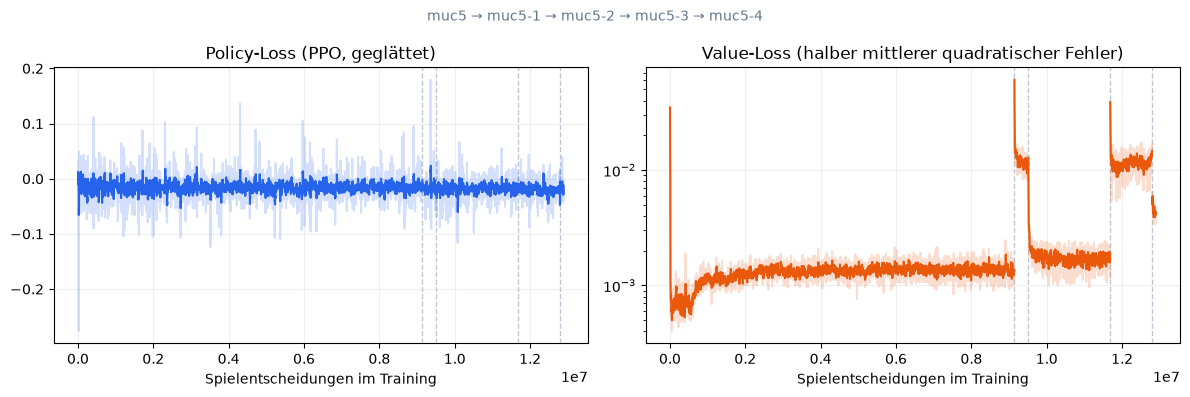

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_metric(axes[0], "policy_loss", smooth=True, color="#2563eb")
plot_metric(axes[1], "value_loss", smooth=True, color="#ea580c")
axes[0].set_title("Policy-Loss (PPO, geglättet)")
axes[1].set_title("Value-Loss (halber mittlerer quadratischer Fehler)")
axes[1].set_yscale("log")
finish(fig, "loss", time_axes=axes.flat)


## Gesamtloss und Spielleistung

Training spielt stochastisch; die periodische Validierung wählt jeweils die wahrscheinlichste Aktion. Unterschiede zwischen beiden Kurven können dadurch entstehen. Die Validierung verwendet feste, vom Training getrennte Seeds. Wiederholte Auswahl von Checkpoints anhand dieser Seeds macht sie zu **Validierungsdaten**, nicht zu einem unabhängigen Abschlusstest.

Eine weitere erreichte Runde ist eine Diagnosehilfe und ersetzt keinen Sieg.

Der Aufgabenplot zeigt die mittlere Zahl **erledigter Landungsvorbereitungen am Spielende**: Fahrwerksabschnitte, Klappenabschnitte, Mindestbremswirkung und entfernte Flugzeuge. Auf MUC sind es aktuell insgesamt 16 Aufgaben (3 + 4 + 1 + 8); vor der Erleichterung des Startfelds waren es 17. Bereits abgeschlossene Aufgaben zählen bei erneuter Belegung nicht nochmals. Die gestrichelte grüne Linie markiert die maximal mögliche Aufgabenzahl; die y-Achse endet 0,1 darüber. Für ältere Logs ohne Aufgabenkennzahlen bleibt dieser Plot leer.

Die Spielübersicht enthält sechs Plots in drei Zeilen und zwei Spalten: Gesamtloss, erreichte Runde, erledigte Aufgaben, Restentfernung, Navigationsfortschritt und die Verlustgründe der letzten vollständigen Validierung. „Mindestens ein Feld zurückgelegt“ vergleicht die Restentfernung bei Spielende mit der Startentfernung der gewählten Strecke. Fehlende historische Kennzahlen werden nicht als null interpretiert.

Der **PPO-Gesamtloss** wird aus den protokollierten Anteilen mit den Gewichten des Laufs berechnet: `Policy-Loss + value_coef × Value-Loss − entropy_coef × Entropie`. Er kann negativ sein. Deshalb zeigt `symlog` beide Vorzeichen logarithmisch und einen kleinen Bereich um null linear; negative Werte werden weder entfernt noch durch ihren Betrag ersetzt. Die blasse Linie zeigt die Rohwerte, die kräftige Linie den geglätteten Verlauf. Bei mehreren Runs gelten die jeweiligen Gewichte; die Glättung überbrückt keine Run-Grenzen.


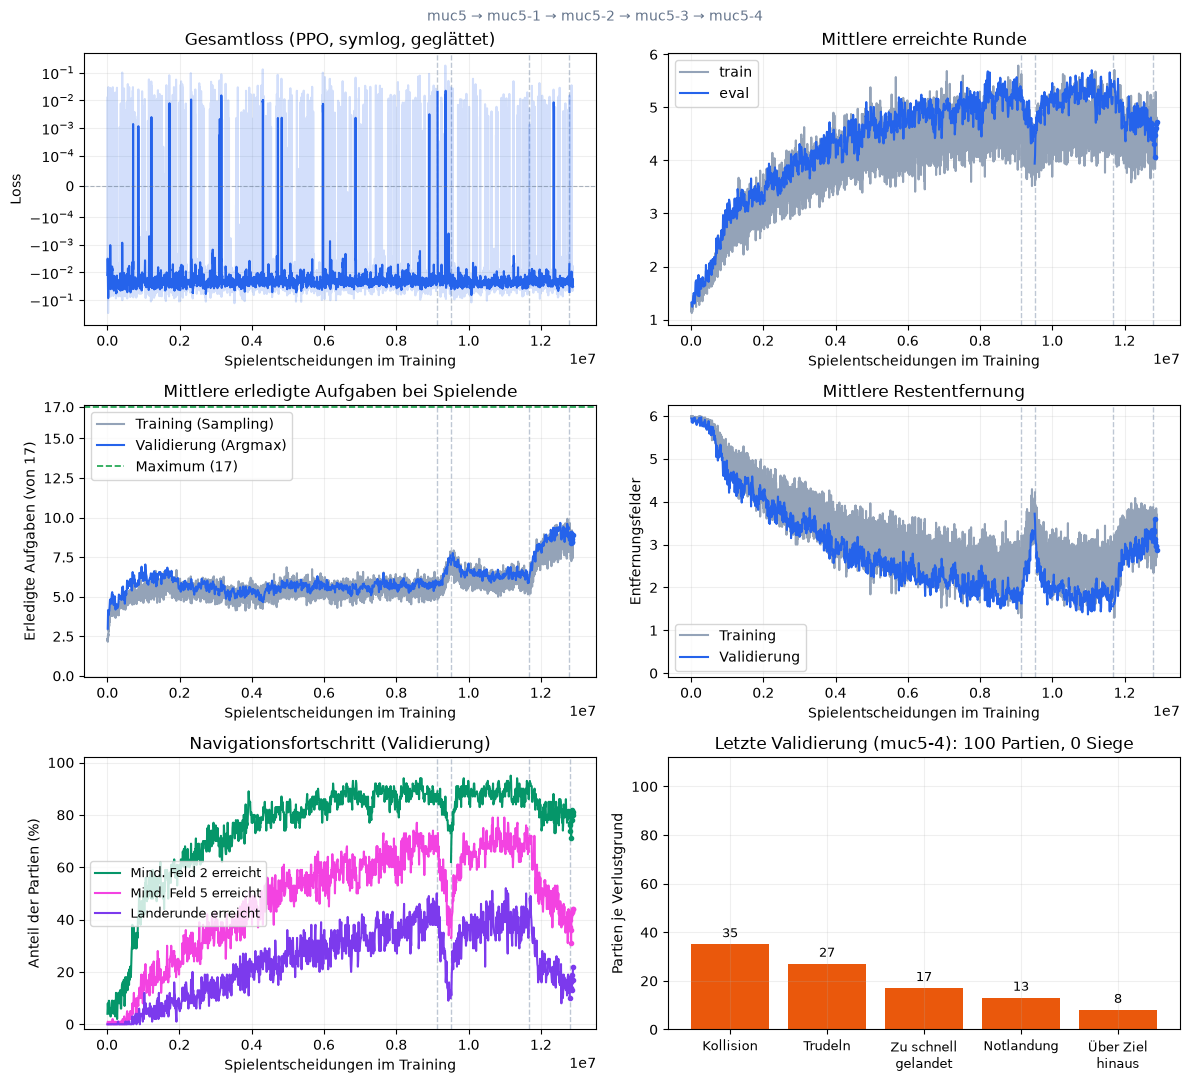

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(12, 11))
plot_metric(axes[0, 0], "total_loss", "PPO-Gesamtloss", smooth=True, color="#2563eb")
axes[0, 0].set_yscale("symlog", linthresh=1e-4)
axes[0, 0].axhline(0, color="#64748b", linewidth=0.8, linestyle="--", alpha=0.5)
axes[0, 0].set(title="Gesamtloss (PPO, symlog, geglättet)", ylabel="Loss")
validation_rows = [r for r in metrics if math.isfinite(number(r, "eval_win_rate"))]
for phase, color in [("train", "#94a3b8"), ("eval", "#2563eb")]:
    plot_metric(axes[0, 1], f"{phase}_mean_round", phase, color=color)
axes[0, 1].set_title("Mittlere erreichte Runde")
axes[0, 1].legend()

for phase, label, color in [("train", "Training (Sampling)", "#94a3b8"),
                            ("eval", "Validierung (Argmax)", "#2563eb")]:
    plot_metric(axes[1, 0], f"{phase}_mean_tasks_done", label, color=color)
task_data_available = bool(axes[1, 0].lines)
axes[1, 0].set(title="Mittlere erledigte Aufgaben bei Spielende",
               ylabel=f"Erledigte Aufgaben (von {TOTAL_TASKS})", ylim=(-0.1, TOTAL_TASKS + 0.1))
axes[1, 0].axhline(TOTAL_TASKS, color="#16a34a", linestyle="--", linewidth=1.2,
                   label=f"Maximum ({TOTAL_TASKS})")
task_ticks = [tick for tick in axes[1, 0].get_yticks() if 0 <= tick < TOTAL_TASKS]
axes[1, 0].set_yticks([*task_ticks, TOTAL_TASKS])
if task_data_available:
    axes[1, 0].legend()
else:
    axes[1, 0].text(0.5, 0.5, "Keine Aufgabenkennzahlen in diesen Logs",
                    ha="center", va="center", transform=axes[1, 0].transAxes)

for phase, label, color in [("train", "Training", "#94a3b8"),
                            ("eval", "Validierung", "#2563eb")]:
    plot_metric(axes[1, 1], f"{phase}_mean_distance_remaining", label, color=color)
axes[1, 1].set(title="Mittlere Restentfernung", ylabel="Entfernungsfelder",
               ylim=(-0.1, max(1, INITIAL_DISTANCE) + 0.25))
if axes[1, 1].lines:
    axes[1, 1].legend()
else:
    axes[1, 1].text(0.5, 0.5, "Keine Entfernungsdaten in diesen Logs",
                    ha="center", va="center", transform=axes[1, 1].transAxes)


validation_by_update = defaultdict(list)
for record in episodes:
    if record["phase"] == "eval":
        validation_by_update[update_key(record)].append(record)
for row in validation_rows:
    distances = [number(record, "distance_remaining") for record in validation_by_update[update_key(row)]
                 if math.isfinite(number(record, "distance_remaining"))]
    if distances:
        row["eval_moved_1_rate"] = np.mean(np.array(distances) < INITIAL_DISTANCE)
        row["eval_moved_4_rate"] = np.mean(np.array(distances) < (INITIAL_DISTANCE - 3))

for key, label, color in [
        ("eval_moved_1_rate", "Mind. Feld 2 erreicht", "#059669"),
        ("eval_moved_4_rate", "Mind. Feld 5 erreicht", "#f343e1"),
        ("eval_landing_round_rate", "Landerunde erreicht", "#7c3aed")]:
    plot_metric(axes[2, 0], key, label, scale=100, color=color)
axes[2, 0].set(title="Navigationsfortschritt (Validierung)", ylabel="Anteil der Partien (%)",
               xlabel="Spielentscheidungen im Training", ylim=(-2, 102))
if axes[2, 0].lines:
    axes[2, 0].legend(fontsize=9, loc="center left")
else:
    axes[2, 0].text(0.5, 0.5, "Keine Navigationsdaten in diesen Logs",
                    ha="center", va="center", transform=axes[2, 0].transAxes)

latest_validation_row = validation_rows[-1] if validation_rows else None
latest_validation = validation_by_update.get(update_key(latest_validation_row), []) if latest_validation_row else []
reason_labels = {
    "trudeln": "Trudeln", "kollision": "Kollision", "notlandung": "Notlandung",
    "zu_schnell_gelandet": "Zu schnell\ngelandet", "uebers_ziel_hinaus": "Über Ziel\nhinaus",
    "pflichtfelder_nicht_erfuellt": "Pflichtfelder\nnicht erfüllt",
    "ruder_verbotene_stellung": "Verbotene\nFluglage", "flugzeuge_uebrig": "Flugzeuge\nübrig",
    "fahrwerk_unvollstaendig": "Fahrwerk\nunvollständig",
    "landeklappen_unvollstaendig": "Klappen\nunvollständig",
    "nicht_waagerecht": "Nicht\nwaagerecht", "step_limit": "Schrittlimit",
    "no_legal_actions": "Keine erlaubte\nAktion",
}
reasons = Counter(reason for record in latest_validation
                  for reason in (record.get("reason") or "").split(",") if reason)
if latest_validation:
    wins = sum(record["status"] == "gewonnen" for record in latest_validation)
    axes[2, 1].set_title(f"Letzte Validierung ({latest_validation_row['run_name']}): {len(latest_validation)} Partien, {wins} Siege")
    if reasons:
        items = reasons.most_common()
        bars = axes[2, 1].bar([reason_labels.get(reason, reason.replace("_", " ")) for reason, _ in items],
                              [count for _, count in items], color="#ea580c")
        axes[2, 1].bar_label(bars, padding=3, fontsize=9)
        axes[2, 1].tick_params(axis="x", labelsize=9)
    else:
        axes[2, 1].text(0.5, 0.5, "Keine Niederlagen", ha="center", va="center",
                        transform=axes[2, 1].transAxes)
    axes[2, 1].set(ylabel="Partien je Verlustgrund", ylim=(0, max(1, len(latest_validation)) * 1.12))
else:
    axes[2, 1].set_title("Verlustgründe der letzten Validierung")
    axes[2, 1].text(0.5, 0.5, "Noch keine vollständige Validierung", ha="center", va="center",
                    transform=axes[2, 1].transAxes)
finish(fig, "performance", time_axes=[*axes[0], *axes[1], axes[2, 0]])


## Stabilität und Exploration

Entropie beschreibt die Streuung über erlaubte Aktionen; sie hängt auch von der Anzahl legaler Aktionen ab. KL-Divergenz und Clip-Anteil zeigen, wie stark PPO die Strategie ändert. Explained Variance bewertet die Value-Vorhersagen auf dem zuletzt gesammelten Rollout; ein negativer Wert bedeutet hier eine schlechtere Vorhersage als ein konstanter Mittelwert. Die Gradientennorm wird vor dem Clipping protokolliert.


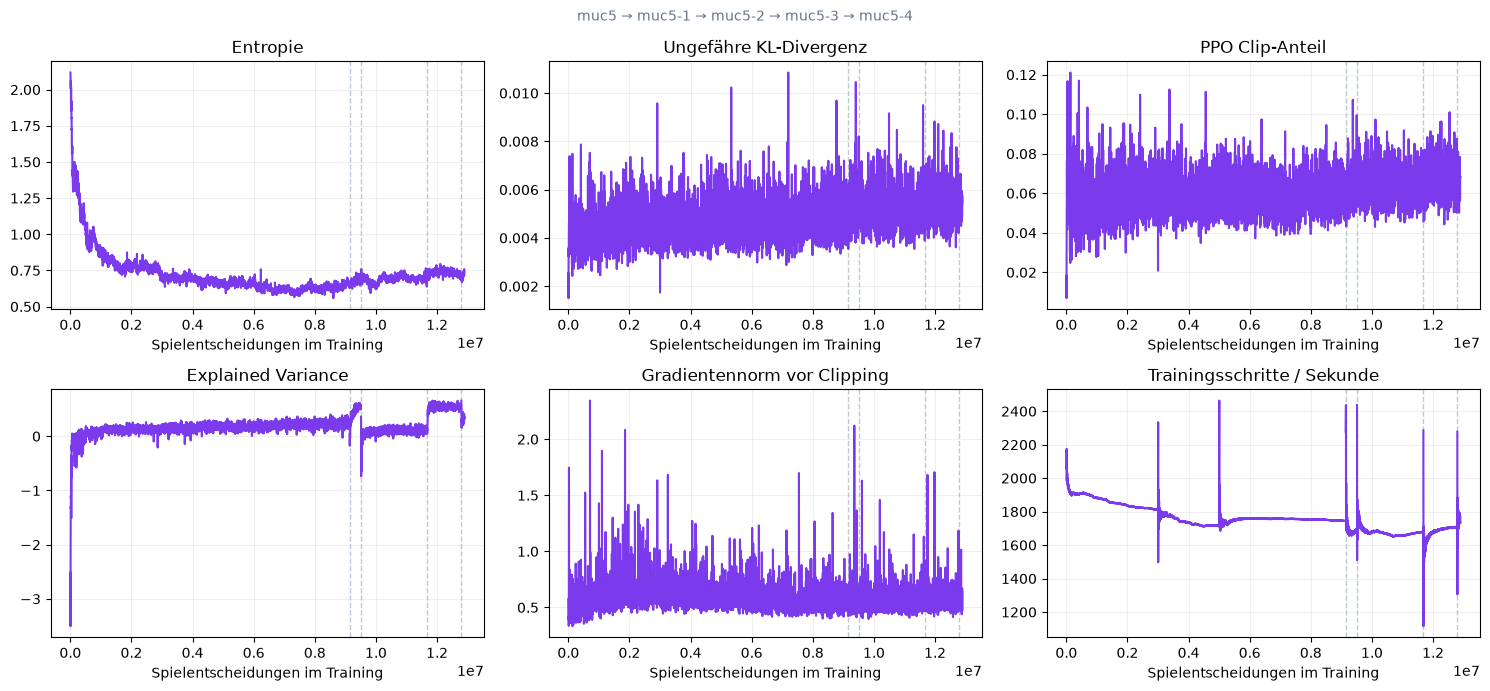

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, key, title in zip(axes.flat,
        ["entropy", "approx_kl", "clip_fraction", "explained_variance", "grad_norm", "steps_per_second"],
        ["Entropie", "Ungefähre KL-Divergenz", "PPO Clip-Anteil", "Explained Variance", "Gradientennorm vor Clipping", "Trainingsschritte / Sekunde"]):
    plot_metric(ax, key, color="#7c3aed")
    ax.set_title(title)
finish(fig, "stability", time_axes=axes.flat)


## Verlustgründe und Spielverläufe

Links stehen die letzten bis zu 500 Trainingspartien, rechts nur die letzte vollständige Validierungsrunde. So werden frühe Trainingsfehler und wiederholt ausgewertete Seeds nicht unbemerkt zusammengezählt. Ein Spiel kann mehrere abschließende Verlustgründe haben. Bei mehreren Runs gelten die letzten 500 Trainingspartien des gemeinsamen Verlaufs und die letzte vollständige Validierung in der gewählten Run-Reihenfolge; im Titel steht der zugehörige Run.


Training (letzte 500) {'verloren': 500}
Letzte Validierung (muc5-4) {'verloren': 100}


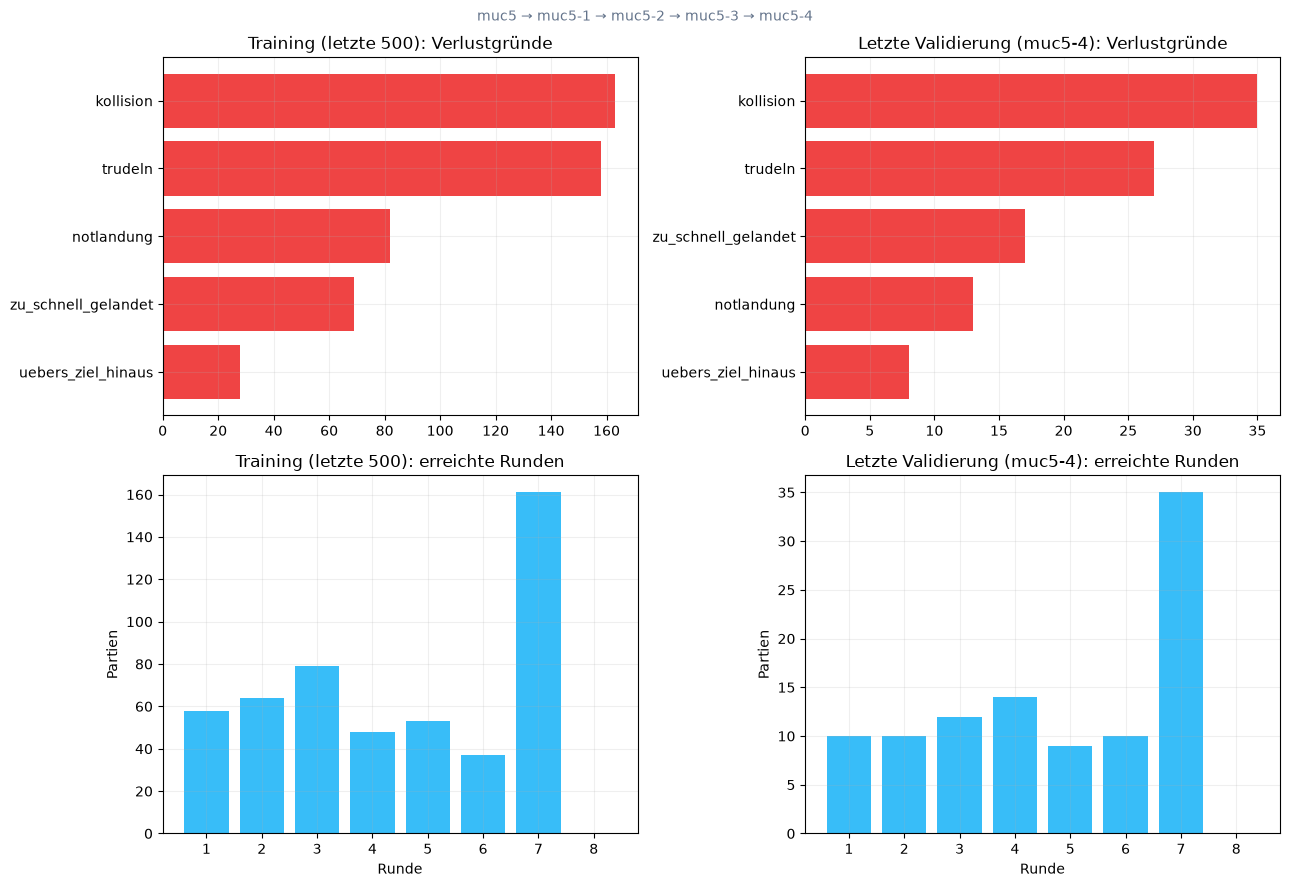

In [ ]:
train_episodes = [r for r in episodes if r.get("phase") == "train"][-500:]
eval_episodes = latest_validation
eval_label = f"Letzte Validierung ({latest_validation_row['run_name']})" if latest_validation_row else "Letzte Validierung"
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, (label, records) in enumerate([("Training (letzte 500)", train_episodes), (eval_label, eval_episodes)]):
    reasons = Counter(reason for r in records for reason in r.get("reason", "").split(",") if reason)
    if reasons:
        names, counts = zip(*reasons.most_common(8))
        axes[0, col].barh(names[::-1], counts[::-1], color="#ef4444")
    else:
        axes[0, col].text(0.5, 0.5, "Keine Verlustgründe vorhanden", ha="center", transform=axes[0, col].transAxes)
    axes[0, col].set_title(f"{label}: Verlustgründe")
    rounds = [int(r["round"]) for r in records]
    axes[1, col].hist(rounds, bins=np.arange(0.5, 9.5, 1), color="#38bdf8", rwidth=0.8)
    axes[1, col].set(title=f"{label}: erreichte Runden", xlabel="Runde", ylabel="Partien")
    print(label, dict(Counter(r["status"] for r in records)))
finish(fig, "outcomes")


## Separate Tests und Vergleich mit anderen Partnern

Speichere abschließende Auswertungen im Unterordner `evaluations` deines Laufs, zum Beispiel aus dem Projektordner:

```bash
.venv/bin/python -m ai.evaluate --checkpoint runs/muc/best.pt --games 500 --json runs/muc/evaluations/self.json
.venv/bin/python -m ai.evaluate --checkpoint runs/muc/best.pt --partner heuristic --ai-role both --games 200 --json runs/muc/evaluations/heuristic-partner.json
.venv/bin/python -m ai.evaluate --baseline heuristic --games 200 --json runs/muc/evaluations/heuristic-baseline.json
```

Bei mehreren ausgewählten Runs werden die Testberichte aller Runs mit ihrem Run-Namen angezeigt.

Bei einem fremden Partner bedeutet `--ai-role both`: die angegebene Zahl Partien **pro Rolle**. Die Standard-Seeds für diese Tests beginnen bei 2.000.000; für die Trainingsvalidierung bei 1.000.000. Für belastbare Aussagen mehrere unabhängige Trainingsläufe vergleichen.


In [ ]:
reports = []
for run in runs:
    for path in sorted((run.directory / "evaluations").glob("*.json")):
        data = json.loads(path.read_text())
        name = f"{run.name} / {path.stem}" if len(runs) > 1 else path.stem
        reports.append((name, data))
        low, high = data["win_ci_low"], data["win_ci_high"]
        print(f'{name}: {data["wins"]}/{data["games"]} Siege; 95%-Intervall {low:.1%}–{high:.1%}; Runde {data["mean_round"]:.2f}')
        for role in ["pilot", "kopilot"]:
            records = [r for r in data.get("episodes", []) if r["ai_role"] == role]
            if records:
                wins = sum(r["status"] == "gewonnen" for r in records)
                print(f"  {role}: {wins}/{len(records)}")
if reports:
    fig, ax = plt.subplots(figsize=(11, 4))
    for i, (name, data) in enumerate(reports):
        value = data["win_rate"]
        ax.errorbar(i, value, yerr=[[max(0, value-data["win_ci_low"])], [max(0, data["win_ci_high"]-value)]],
                    fmt="o", capsize=5, label=name)
    ax.set_xticks(range(len(reports)), [name for name, _ in reports], rotation=15, ha="right")
    ax.set(title="Abschlusstests mit 95%-Intervallen", ylabel="Gewinnrate", ylim=(-0.02, 1.02))
    finish(fig, "held-out-tests")
else:
    print("Noch keine zusätzlichen Testberichte. Die Befehle darüber erzeugen sie.")


Noch keine zusätzlichen Testberichte. Die Befehle darüber erzeugen sie.
